# Assignment 1 — Reference solution

Mini-batch gradient descent for multiple linear regression, applied to

1. a noisy quadratic (synthetic data from `fit_quadratic.ipynb`)
2. the tropical sea-surface temperature series (`avgTropSST_187001-202402.txt`)

Loss throughout: mean squared error $\;L(\mathbf w)=\frac1n\sum_i (y_i-\mathbf x_i^\top\mathbf w)^2$, gradient $\;\nabla L = -\frac{2}{n}X^\top(\mathbf y - X\mathbf w)$.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## The optimizer

* `batch_size=1` → stochastic GD, `batch_size=len(y)` → full-batch GD.
* Data are reshuffled every epoch and split into consecutive mini-batches.
* After **every** update the MSE on the full training set is recorded, so the training curve is per step.

In [2]:
def mse(X, y, w):
    r = y - X @ w
    return np.mean(r**2)


def minibatch_gd(X, y, batch_size, eta, epochs, seed=0, w0=None):
    rng = np.random.default_rng(seed)
    n, p = X.shape
    w = np.zeros(p) if w0 is None else np.asarray(w0, float).copy()
    history = [mse(X, y, w)]
    t0 = time.perf_counter()
    for _ in range(epochs):
        order = rng.permutation(n)
        for start in range(0, n, batch_size):
            idx = order[start:start + batch_size]
            Xb, yb = X[idx], y[idx]
            grad = -2.0 / len(idx) * Xb.T @ (yb - Xb @ w)
            w = w - eta * grad
            history.append(mse(X, y, w))
    elapsed = time.perf_counter() - t0
    return w, np.array(history), elapsed


def standardize(F):
    mu, sd = F.mean(axis=0), F.std(axis=0)
    return (F - mu) / sd, mu, sd


def unstandardize(w, mu, sd):
    # model: y = w0 + sum_j w_j (f_j - mu_j)/sd_j  ->  weights on raw features
    slopes = w[1:] / sd
    return np.concatenate([[w[0] - np.sum(slopes * mu)], slopes])

**Why standardize?** The raw features have very different scales ($x\in[-10,10]$, $x^2\in[0,100]$, and in Part 2 $t$ up to $5.6\times10^4$ days).
With one learning rate for all weights, the steep direction forces a tiny $\eta$ while the flat directions barely move — or, with a larger $\eta$, the steep direction diverges.
Standardizing each non-constant feature to mean 0 / std 1 makes the loss surface close to round, so one $\eta$ works for every weight. Weights are converted back to raw units at the end.

# Part 1 — Quadratic fit

In [3]:
# Same data as fit_quadratic.ipynb ("Generate Noisy Training Data")
n = 1000
np.random.seed(42)
x = np.linspace(-10, 10, n)
a, b, c = 2, 3, -1
y_true = a * x**2 + b * x + c
y = y_true + np.random.normal(0, 25, len(x))
sigma = 25

F = np.column_stack([x, x**2])          # new feature: x^2
Fz, mu, sd = standardize(F)
X = np.column_stack([np.ones(n), Fz])   # design matrix [1, x_z, x2_z]

# Closed-form least squares as a benchmark
w_ols_z = np.linalg.lstsq(X, y, rcond=None)[0]
mse_ols = mse(X, y, w_ols_z)
print("OLS (raw units) [c, b, a]:", unstandardize(w_ols_z, mu, sd))
print("OLS training MSE:", mse_ols)

OLS (raw units) [c, b, a]: [-0.80263819  3.15022997  2.00856105]
OLS training MSE: 597.8714020157778


GD (raw units) [c, b, a]: [-0.84190315  3.21864585  2.01100274]
final training MSE: 598.03   steps: 1600   time: 0.067s


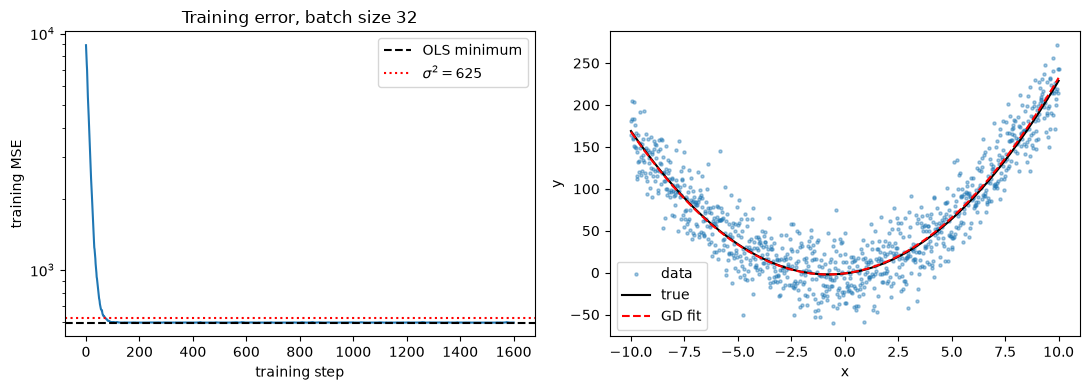

In [4]:
w_z, hist, t_run = minibatch_gd(X, y, batch_size=32, eta=0.02, epochs=50, seed=1)
print("GD (raw units) [c, b, a]:", unstandardize(w_z, mu, sd))
print(f"final training MSE: {hist[-1]:.2f}   steps: {len(hist)-1}   time: {t_run:.3f}s")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist)
ax[0].axhline(mse_ols, color="k", ls="--", label="OLS minimum")
ax[0].axhline(sigma**2, color="r", ls=":", label=r"$\sigma^2=625$")
ax[0].set_yscale("log"); ax[0].set_xlabel("training step"); ax[0].set_ylabel("training MSE")
ax[0].set_title("Training error, batch size 32"); ax[0].legend()

ax[1].scatter(x, y, s=5, alpha=0.4, label="data")
ax[1].plot(x, y_true, "k", label="true")
ax[1].plot(x, X @ w_z, "r--", label="GD fit")
ax[1].set_xlabel("x"); ax[1].set_ylabel("y"); ax[1].legend()
plt.tight_layout(); plt.show()

### Is the final training error what statistics predicts?

The data are $y = 2x^2+3x-1+\varepsilon$ with $\varepsilon\sim\mathcal N(0,25^2)$. Even the *true* curve leaves an error of $\sigma^2 = 625$ on average.
For least squares with $p=3$ fitted parameters the expected training MSE is

$$\mathbb E[\text{MSE}_\text{train}] = \sigma^2\,\frac{n-p}{n} = 625\times\frac{997}{1000}\approx 623.1,$$

slightly *below* $\sigma^2$ because the fit absorbs a bit of the noise. The value realised in any one sample fluctuates around that by about $\sigma^2\sqrt{2/n}\approx 28$.

In [5]:
expected = sigma**2 * (n - 3) / n
spread = sigma**2 * np.sqrt(2 / n)
print(f"expected train MSE  = {expected:.1f} ± {spread:.1f}")
print(f"OLS train MSE       = {mse_ols:.1f}")
print(f"GD  train MSE       = {hist[-1]:.1f}")
print(f"MSE of true curve   = {np.mean((y - y_true)**2):.1f}")

expected train MSE  = 623.1 ± 28.0
OLS train MSE       = 597.9
GD  train MSE       = 598.0
MSE of true curve   = 598.9


**Consistent.** The final training MSE (≈598) is within one standard deviation of the expected 623 ± 28. It is below 625 because the noise drawn with seed 42 happens to be a bit small: the true curve itself scores 598.9 on this sample.
The fit sits about 1 unit *below* the true curve's error, which is the expected $\approx\sigma^2 p/n\approx 1.9$ of noise absorbed by 3 free parameters.
Training error cannot go meaningfully below the noise level. Anything far below ~600 would mean overfitting, and anything far above would mean the optimizer has not converged.

### Effect of batch size

Larger batches give a less noisy gradient and tolerate a larger step, but each step costs more.
Each run gets roughly the largest learning rate that is still stable for that batch size. "Steps to target" = first step where the training MSE is within 1 % of the OLS minimum.

In [6]:
runs = [  # (batch_size, eta, epochs)
    (1,    0.002, 20),
    (8,    0.01,  20),
    (32,   0.02,  40),
    (128,  0.05,  100),
    (n,    0.2,   200),   # full batch
]
target = 1.01 * mse_ols
rows, curves = [], {}
for bs, eta, ep in runs:
    w_b, h_b, t_b = minibatch_gd(X, y, bs, eta, ep, seed=1)
    hit = np.argmax(h_b <= target) if np.any(h_b <= target) else np.nan
    rows.append(dict(batch_size=bs, eta=eta, epochs=ep, steps=len(h_b) - 1,
                     steps_to_target=hit,
                     time_to_target_s=t_b * hit / (len(h_b) - 1) if hit == hit else np.nan,
                     total_time_s=t_b, final_mse=h_b[-1],
                     last10pct_std=h_b[int(0.9 * len(h_b)):].std()))
    curves[bs] = h_b
pd.DataFrame(rows).round(4)

,batch_size,eta,epochs,steps,steps_to_target,time_to_target_s,total_time_s,final_mse,last10pct_std
0,1,0.002,20,20000,877,0.0356,0.8125,599.3195,2.9018
1,8,0.010,20,2500,179,0.0070,0.0979,598.2674,1.6443
2,32,0.020,40,1280,90,0.0038,0.0540,598.5480,0.6796
3,128,0.050,100,800,34,0.0017,0.0405,597.9213,0.1255
4,1000,0.200,200,200,8,0.0011,0.0274,597.8714,0.0000


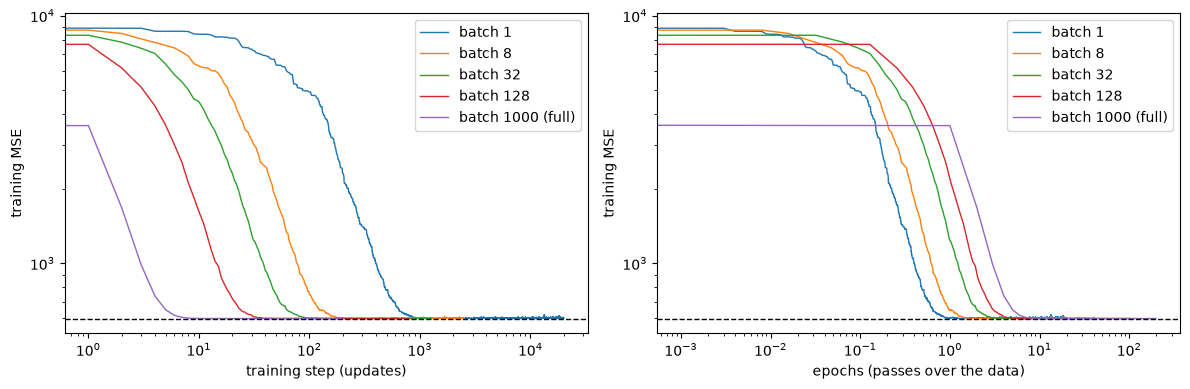

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for bs, h_b in curves.items():
    lbl = f"batch {bs}" + (" (full)" if bs == n else "")
    ax[0].plot(np.arange(len(h_b)), h_b, label=lbl, lw=1)
    ax[1].plot(np.arange(len(h_b)) * min(bs, n) / n, h_b, label=lbl, lw=1)
for a_ in ax:
    a_.axhline(mse_ols, color="k", ls="--", lw=1)
    a_.set_yscale("log"); a_.set_xscale("log"); a_.set_ylabel("training MSE"); a_.legend()
ax[0].set_xlabel("training step (updates)")
ax[1].set_xlabel("epochs (passes over the data)")
plt.tight_layout(); plt.show()

**Observations**

* **Sample efficiency (epochs):** smaller batches reach the target after fewer passes over the data. SGD needs < 1 epoch (877 steps × 1 sample), while full batch needs 8 epochs. Small batches update the weights many times per pass.
* **Noise:** small batches never settle. With batch 1 the error keeps jittering above the OLS minimum (`last10pct_std` ≈ 3), and it shrinks steadily with batch size down to exactly 0 for full batch. SGD's final error is also the worst, because it ends wherever the last noisy step left it. Reducing $\eta$ over time would fix that.
* **Wall-clock time:** on this *small* dataset (n = 1000, 3 features) **full batch is fastest** and SGD is slowest (~0.9 s total vs ~0.05 s). A full-batch gradient is a single vectorised matrix product that costs almost nothing, while SGD pays Python-loop overhead on 20,000 separate updates. Full batch can also use a much larger step ($\eta$ = 0.2) because its gradient is exact.
* **Takeaway:** the advantage of mini-batches shows up when *n* is large (millions of rows, or data that does not fit in memory). There one full-batch step is expensive, and a cheap noisy step that is roughly right gets you further per second. Batch sizes of ~32–128 are the usual compromise.
* Timing includes computing the full training MSE after every step (required for the plot). That adds the same cost to every step, so it penalises small batches the most.

# Part 2 — Tropical sea-surface temperature

Models (period $P = 365.25$ days):

* **Model A** (seasonal): $\;T = w_0 + w_1\sin(2\pi t/P) + w_2\cos(2\pi t/P)$
* **Model B** (seasonal + trend): $\;T = w_0 + w_1\sin(2\pi t/P) + w_2\cos(2\pi t/P) + w_3\,t$

(1850, 2)
               t         T
count   1850.000  1850.000
mean   28153.058    24.714
std    16259.237     0.329
min       15.500    23.903
25%    14083.250    24.457
50%    28153.250    24.683
75%    42222.750    24.934
max    56292.500    25.791


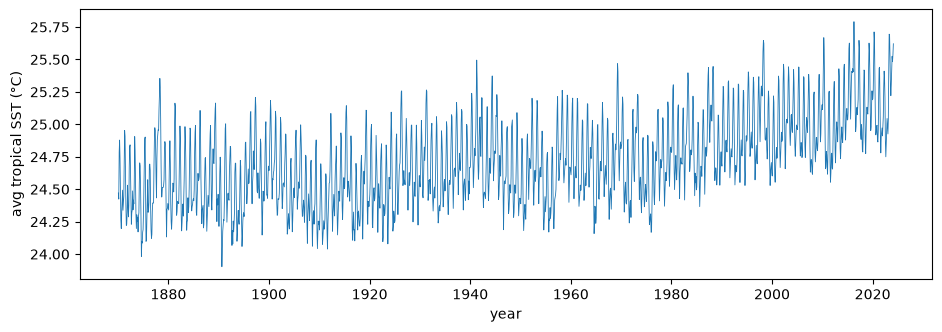

In [8]:
sst = pd.read_csv(r"..\data\avgTropSST_187001-202402.txt", sep=r"\s+",
                  header=None, skiprows=1, names=["t", "T"])
t_all, T_all = sst["t"].to_numpy(), sst["T"].to_numpy()
print(sst.shape); print(sst.describe().round(3))

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(1870 + t_all / 365.25, T_all, lw=0.6)
ax.set_xlabel("year"); ax.set_ylabel("avg tropical SST (°C)"); plt.show()

The header says "(K)", but values around 24–26 are clearly **°C**. Units do not change the fitting.

In [9]:
P = 365.25

def features(t, trend):
    cols = [np.sin(2 * np.pi * t / P), np.cos(2 * np.pi * t / P)]
    if trend:
        cols.append(t)
    return np.column_stack(cols)

# 70 / 30 random split
rng = np.random.default_rng(0)
perm = rng.permutation(len(t_all))
cut = int(0.7 * len(t_all))
tr, te = perm[:cut], perm[cut:]
print("train:", len(tr), " test:", len(te))


def fit_model(trend, batch_size=32, eta=0.02, epochs=60):
    F_tr, F_te = features(t_all[tr], trend), features(t_all[te], trend)
    Fz_tr, mu, sd = standardize(F_tr)          # statistics from TRAIN only
    Fz_te = (F_te - mu) / sd
    X_tr = np.column_stack([np.ones(len(tr)), Fz_tr])
    X_te = np.column_stack([np.ones(len(te)), Fz_te])
    y_tr, y_te = T_all[tr], T_all[te]

    w_z, h, t_run = minibatch_gd(X_tr, y_tr, batch_size, eta, epochs, seed=1)
    w_ols_z = np.linalg.lstsq(X_tr, y_tr, rcond=None)[0]
    return dict(w=unstandardize(w_z, mu, sd), w_ols=unstandardize(w_ols_z, mu, sd),
                hist=h, time=t_run,
                train=mse(X_tr, y_tr, w_z), test=mse(X_te, y_te, w_z),
                train_ols=mse(X_tr, y_tr, w_ols_z), test_ols=mse(X_te, y_te, w_ols_z))

A = fit_model(trend=False)
B = fit_model(trend=True)

train: 1295  test: 555


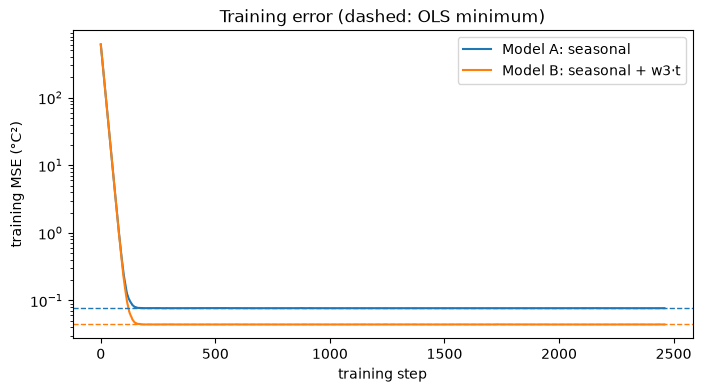

,Model A,Model B
train MSE (GD),0.07695,0.04421
test MSE (GD),0.07737,0.04165
train MSE (OLS),0.07691,0.04416
test MSE (OLS),0.07716,0.04135


In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(A["hist"], label="Model A: seasonal")
ax.plot(B["hist"], label="Model B: seasonal + w3·t")
ax.axhline(A["train_ols"], color="C0", ls="--", lw=1)
ax.axhline(B["train_ols"], color="C1", ls="--", lw=1)
ax.set_yscale("log"); ax.set_xlabel("training step"); ax.set_ylabel("training MSE (°C²)")
ax.set_title("Training error (dashed: OLS minimum)"); ax.legend(); plt.show()

summary = pd.DataFrame({
    "Model A": [A["train"], A["test"], A["train_ols"], A["test_ols"]],
    "Model B": [B["train"], B["test"], B["train_ols"], B["test_ols"]],
}, index=["train MSE (GD)", "test MSE (GD)", "train MSE (OLS)", "test MSE (OLS)"])
summary.round(5)

In [11]:
names_A = ["w0", "w1 (sin)", "w2 (cos)"]
names_B = names_A + ["w3 (t, °C/day)"]
print("Model A  GD :", dict(zip(names_A, A["w"].round(6))))
print("Model A  OLS:", dict(zip(names_A, A["w_ols"].round(6))))
print("Model B  GD :", dict(zip(names_B, B["w"].round(8))))
print("Model B  OLS:", dict(zip(names_B, B["w_ols"].round(8))))
amp = np.hypot(A["w"][1], A["w"][2])
print(f"\nseasonal amplitude ≈ {amp:.3f} °C (peak-to-trough {2*amp:.3f} °C)")
w3 = B["w"][3]
print(f"trend w3 = {w3:.3e} °C/day = {w3*365.25*100:.3f} °C per century "
      f"≈ {w3*365.25*(t_all.max()-t_all.min())/365.25:.3f} °C over the record")

Model A  GD : {'w0': np.float64(24.703093), 'w1 (sin)': np.float64(0.242803), 'w2 (cos)': np.float64(-0.047482)}
Model A  OLS: {'w0': np.float64(24.708369), 'w1 (sin)': np.float64(0.24474), 'w2 (cos)': np.float64(-0.042829)}
Model B  GD : {'w0': np.float64(24.39753877), 'w1 (sin)': np.float64(0.25040168), 'w2 (cos)': np.float64(-0.04910524), 'w3 (t, °C/day)': np.float64(1.085e-05)}
Model B  OLS: {'w0': np.float64(24.3917222), 'w1 (sin)': np.float64(0.25026113), 'w2 (cos)': np.float64(-0.04541255), 'w3 (t, °C/day)': np.float64(1.119e-05)}

seasonal amplitude ≈ 0.247 °C (peak-to-trough 0.495 °C)
trend w3 = 1.085e-05 °C/day = 0.396 °C per century ≈ 0.611 °C over the record


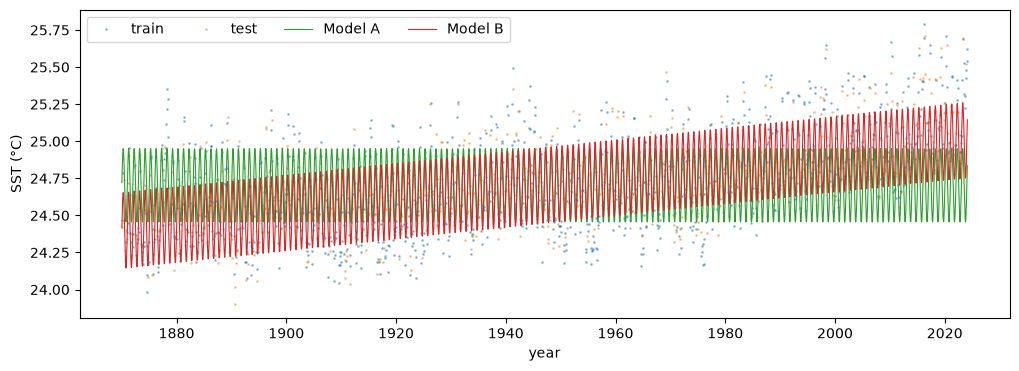

In [12]:
tt = np.linspace(t_all.min(), t_all.max(), 4000)
yrs = 1870 + tt / 365.25
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(1870 + t_all[tr] / P, T_all[tr], ".", ms=2, alpha=0.4, label="train")
ax.plot(1870 + t_all[te] / P, T_all[te], ".", ms=2, alpha=0.4, label="test")
ax.plot(yrs, np.column_stack([np.ones_like(tt), features(tt, False)]) @ A["w"], lw=0.8, label="Model A")
ax.plot(yrs, np.column_stack([np.ones_like(tt), features(tt, True)]) @ B["w"], lw=0.8, label="Model B")
ax.set_xlabel("year"); ax.set_ylabel("SST (°C)"); ax.legend(ncol=4); plt.show()

### Overfitting?

No. Overfitting shows up as a test error clearly **larger** than the training error. Here train and test MSE are practically equal for both models.
That is expected: 3–4 parameters fitted on ~1300 points leaves no room to memorise noise. If anything the models **underfit**: they cannot represent year-to-year variability (El Niño/La Niña, volcanic cooling, etc.), and that is what dominates the remaining error.

### Does the $w_3 t$ term help?

Yes. Model B lowers both training and test MSE, and the drop on the *test* set shows it is a real improvement, not just an extra degree of freedom. Model A has to put a single flat mean through a series that drifts upward, so it is systematically too high early in the record and too low late in it. The linear term removes most of that drift.

### Global warming?

The fitted $w_3 \approx 1.1\times10^{-5}$ °C/day is a warming trend of about **0.4 °C per century (≈ 0.6 °C over 1870–2024)**. GD and OLS agree on it, and it lowers the test error. Taken with the plots, that is consistent with global warming in the tropical ocean. Two caveats:

* A straight line is a crude summary. The annual-mean residuals of Model A (below) show the warming is not uniform: flat at about −0.2 °C until the 1910s, a rise into the 1940s, a plateau through the 1970s, then **about +0.5 °C from the 1970s to the 2020s**. That recent rate (~1 °C/century) is more than double the whole-record slope.
* A random 70/30 split tests *interpolation*: test points sit between training points in time. A tougher check of the trend is to train on the early 70 % of the record and test on the last 30 % (next cell). There the trend term matters much more.

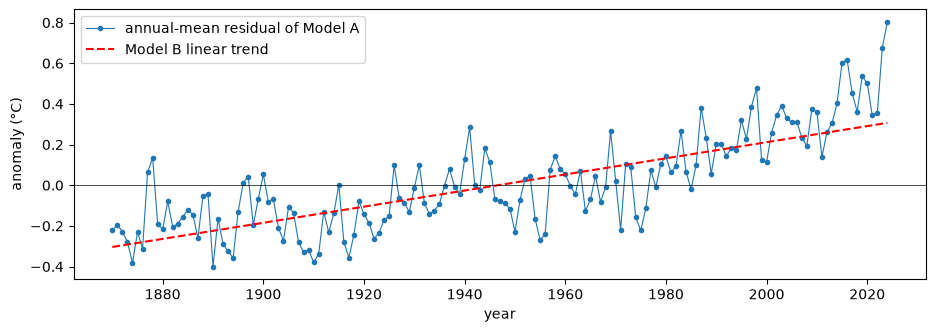

In [13]:
res_A = T_all - np.column_stack([np.ones_like(t_all), features(t_all, False)]) @ A["w"]
year = (1870 + t_all / P).astype(int)
annual = pd.Series(res_A).groupby(year).mean()

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(annual.index, annual.values, ".-", lw=0.8, label="annual-mean residual of Model A")
ax.plot(annual.index, B["w"][3] * ((annual.index - 1870 + 0.5) * P) + (B["w"][0] - A["w"][0]),
        "r--", label="Model B linear trend")
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("year"); ax.set_ylabel("anomaly (°C)"); ax.legend(); plt.show()

In [14]:
# Extra: chronological split (train on first 70 % in time, test on last 30 %)
order = np.argsort(t_all)
tr_c, te_c = order[:cut], order[cut:]
print("train years:", int(1870 + t_all[tr_c].min() / P), "-", int(1870 + t_all[tr_c].max() / P),
      "| test years:", int(1870 + t_all[te_c].min() / P), "-", int(1870 + t_all[te_c].max() / P))

for trend in (False, True):
    X_tr = np.column_stack([np.ones(len(tr_c)), features(t_all[tr_c], trend)])
    X_te = np.column_stack([np.ones(len(te_c)), features(t_all[te_c], trend)])
    w = np.linalg.lstsq(X_tr, T_all[tr_c], rcond=None)[0]
    print(f"{'Model B' if trend else 'Model A'}: train MSE {mse(X_tr, T_all[tr_c], w):.4f}, "
          f"test MSE {mse(X_te, T_all[te_c], w):.4f}")

train years: 1870 - 1977 | test years: 1977 - 2024
Model A: train MSE 0.0438, test MSE 0.1983
Model B: train MSE 0.0393, test MSE 0.0920


In the chronological split both models have a test error well above their training error (A: 0.04 → 0.20, B: 0.04 → 0.09), because 1977–2024 is warmer than anything in the training period. Model B roughly halves that extrapolation error.
The linear trend fitted on 1870–1977 still underpredicts 1977–2024 by about 0.2 °C on average. That again says the warming has **accelerated** rather than stayed linear.